## Read in data from the first round of annotator review

In [1]:
from article_utils.util import read_jsonl
import glob

rounds = []



df = read_jsonl(*[f for f in glob.glob('../data/doccano/15c038a5-6df4-469a-b0d9-4e7116ea1d79/*.jsonl') if not f.endswith('admin.jsonl')], add_filename=True)

names_df = df[['filename']].drop_duplicates()
names_df['curator'] = names_df.filename.str.extract(r'.*/([^.]+)\.jsonl$')

df = df.merge(names_df)
df['example_id'] = df['display_id'] = df.meta.str['example_id']
df['predicted_label_name'] = df.label.str[0].str.upper()
df.loc[df.predicted_label_name == 'NOT ENOUGH INFORMATION', 'predicted_label_name'] = 'NEI'

df = df[~df.predicted_label_name.isna()]
df = df[~df.predicted_label_name.str.startswith('OTHER')]
print(df.predicted_label_name.value_counts(dropna=False))


print(f'there are {df.example_id.nunique()} unique examples')
print(f'there are {df.curator.nunique()} unique curators')
print( 'curators per example', df.groupby(['display_id']).agg({'curator': 'nunique'}).reset_index()[['curator']].value_counts())

df['round'] = '1'
rounds.append(df)
df

predicted_label_name
NEI         117
SUPPORTS     94
REFUTES      66
Name: count, dtype: int64
there are 46 unique examples
there are 7 unique curators
curators per example curator
6          36
7           6
5           3
4           1
Name: count, dtype: int64


,id,text,meta,label,Comments,filename,curator,example_id,display_id,predicted_label_name,round
0,48,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'e3eba2af-7c57-4e19-8dba-931a12...,[Supports],[],../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,Mariam_Khanfar,e3eba2af-7c57-4e19-8dba-931a122cd40d,e3eba2af-7c57-4e19-8dba-931a122cd40d,SUPPORTS,1
1,49,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'f63e8ebf-7b34-417c-b9df-911238...,[Refutes],[The significance in the claim contradicts the...,../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,Mariam_Khanfar,f63e8ebf-7b34-417c-b9df-911238bb710b,f63e8ebf-7b34-417c-b9df-911238bb710b,REFUTES,1
2,50,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'b2f6ede3-a747-4de9-95bb-3e275a...,[Not Enough Information],[The summary does not mention the variant in t...,../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,Mariam_Khanfar,b2f6ede3-a747-4de9-95bb-3e275a488687,b2f6ede3-a747-4de9-95bb-3e275a488687,NEI,1
3,51,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'c40b1b72-4c60-4d2e-804f-ec0288...,[Not Enough Information],[The summary does not have enough information ...,../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,Mariam_Khanfar,c40b1b72-4c60-4d2e-804f-ec02889c526d,c40b1b72-4c60-4d2e-804f-ec02889c526d,NEI,1
4,52,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'd163d0c4-e12f-4fcd-bca3-e955cd...,[Supports],[],../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,Mariam_Khanfar,d163d0c4-e12f-4fcd-bca3-e955cd19941a,d163d0c4-e12f-4fcd-bca3-e955cd19941a,SUPPORTS,1
...,...,...,...,...,...,...,...,...,...,...,...
501,89,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'd68f0ea0-9d84-4943-a2af-02e6be...,[Not Enough Information],[The variant is listed in a table but there ar...,../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,obigriffith,d68f0ea0-9d84-4943-a2af-02e6be33abeb,d68f0ea0-9d84-4943-a2af-02e6be33abeb,NEI,1
502,90,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'f3af5019-73eb-4f5d-b7ba-a6bec5...,[Refutes],[Evidence describes better outcome. Also might...,../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,obigriffith,f3af5019-73eb-4f5d-b7ba-a6bec54ab55c,f3af5019-73eb-4f5d-b7ba-a6bec54ab55c,REFUTES,1
503,91,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'c1dc2ea5-7530-4f97-854c-e4feee...,[Not Enough Information],[No details to support actual functional signi...,../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,obigriffith,c1dc2ea5-7530-4f97-854c-e4feeeeddb9c,c1dc2ea5-7530-4f97-854c-e4feeeeddb9c,NEI,1
504,92,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '90081045-70c0-4e61-b6f6-5a9dc6...,[Supports],[],../data/doccano/15c038a5-6df4-469a-b0d9-4e7116...,obigriffith,90081045-70c0-4e61-b6f6-5a9dc688f82d,90081045-70c0-4e61-b6f6-5a9dc688f82d,SUPPORTS,1


## Read in data from the second round of annotator review

In [2]:
df = read_jsonl(*[f for f in glob.glob('../data/doccano/2023.10.20_IAv2_civicfact2023.10.20/subset-*/*.jsonl') if not f.endswith('admin.jsonl')], add_filename=True)

names_df = df[['filename']].drop_duplicates()
names_df['curator'] = names_df.filename.str.extract(r'.*/([^.]+)\.jsonl$')

df = df.merge(names_df)
df['example_id'] = df['display_id'] = df.meta.str['example_id']
df['predicted_label_name'] = df.label.str[0]

print(f'there are {df.example_id.nunique()} unique examples')
print(f'there are {df.curator.nunique()} unique curators')
print( 'curators per example', df.groupby(['display_id']).agg({'curator': 'nunique'}).reset_index()[['curator']].value_counts())

df['round'] = '2023.10.20'
rounds.append(df)
df


there are 300 unique examples
there are 9 unique curators
curators per example curator
3          300
Name: count, dtype: int64


,id,text,meta,label,Comments,filename,curator,example_id,display_id,predicted_label_name,round
0,9168,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '1b081473-9a3f-466d-80c7-773dbf...,[NEI],[Should be more evidence(s) such as symptoms o...,../data/doccano/2023.10.20_IAv2_civicfact2023....,Mariam_Khanfar,1b081473-9a3f-466d-80c7-773dbf02e801,1b081473-9a3f-466d-80c7-773dbf02e801,NEI,2023.10.20
1,9169,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'e7029c89-5dcc-4921-b021-ece98c...,[SUPPORTS],[],../data/doccano/2023.10.20_IAv2_civicfact2023....,Mariam_Khanfar,e7029c89-5dcc-4921-b021-ece98c927ccb,e7029c89-5dcc-4921-b021-ece98c927ccb,SUPPORTS,2023.10.20
2,9170,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'a1204510-81ba-493d-a4db-aa1963...,[REFUTES],[],../data/doccano/2023.10.20_IAv2_civicfact2023....,Mariam_Khanfar,a1204510-81ba-493d-a4db-aa1963f81f98,a1204510-81ba-493d-a4db-aa1963f81f98,REFUTES,2023.10.20
3,9171,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '2f2e2061-9cfa-49bc-8371-ff19b7...,[REFUTES],[],../data/doccano/2023.10.20_IAv2_civicfact2023....,Mariam_Khanfar,2f2e2061-9cfa-49bc-8371-ff19b7ba041c,2f2e2061-9cfa-49bc-8371-ff19b7ba041c,REFUTES,2023.10.20
4,9172,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '72d8ce19-b86f-48f8-9a56-0f4ed9...,[NEI],[],../data/doccano/2023.10.20_IAv2_civicfact2023....,Mariam_Khanfar,72d8ce19-b86f-48f8-9a56-0f4ed922affd,72d8ce19-b86f-48f8-9a56-0f4ed922affd,NEI,2023.10.20
...,...,...,...,...,...,...,...,...,...,...,...
895,10063,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'efcff7df-e71b-47ec-a0cc-7d7355...,[NEI],[The drug in the claim is too specific. The ev...,../data/doccano/2023.10.20_IAv2_civicfact2023....,creisle,efcff7df-e71b-47ec-a0cc-7d73554d4354,efcff7df-e71b-47ec-a0cc-7d73554d4354,NEI,2023.10.20
896,10064,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': 'f1c8c71b-c921-4cbb-b299-033dc1...,[NEI],[no conclusions are discussed in the evidence],../data/doccano/2023.10.20_IAv2_civicfact2023....,creisle,f1c8c71b-c921-4cbb-b299-033dc19d71e4,f1c8c71b-c921-4cbb-b299-033dc19d71e4,NEI,2023.10.20
897,10065,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '7d470b96-52f7-4160-bc10-72bcfc...,[SUPPORTS],[],../data/doccano/2023.10.20_IAv2_civicfact2023....,creisle,7d470b96-52f7-4160-bc10-72bcfcfff826,7d470b96-52f7-4160-bc10-72bcfcfff826,SUPPORTS,2023.10.20
898,10066,"<div class=""example""><div class=""claim""><h2>Cl...",{'example_id': '2489d6c7-fabc-4a52-b731-295327...,[NEI],[The variants discussed in the evidence are li...,../data/doccano/2023.10.20_IAv2_civicfact2023....,creisle,2489d6c7-fabc-4a52-b731-295327b12c53,2489d6c7-fabc-4a52-b731-295327b12c53,NEI,2023.10.20


## Read in data from the third round of anotator review

In [3]:
other_df = read_jsonl(*[f for f in glob.glob('../data/doccano/2025.01.31_retrieval_review_civicfactpairs-2024.12.22/data/*.jsonl') if not f.endswith('all.jsonl')], add_filename=True).rename(columns={'id': 'doccano.id', 'text': 'doccano.text'})
print(other_df.columns)
meta_df = read_jsonl('../data/doccano/2025.01.31_retrieval_review_civicfactpairs-2024.12.22/data/all.jsonl')
print('other_df', other_df.shape[0])

df = other_df.merge(meta_df)
assert df.shape[0] == other_df.shape[0]
df['label'] = df.label.apply(lambda labels: labels[0] if labels else '')
df['predicted_label_name'] = df.label.str.extract(r'^(\w+)')
df['predicted_label_name'] = df.predicted_label_name.str.upper()
df['curator'] = df.filename.str.extract('data/(\w+)\.jsonl')

df['civic.evidenceDirection'] = df['civic.evidenceDirection'].fillna('SUPPORTS')
df.loc[df['civic.evidenceDirection'] == '', 'civic.evidenceDirection'] = 'SUPPORTS'
df.loc[df['civic.evidenceDirection'] == 'DOES_NOT_SUPPORT', 'civic.evidenceDirection'] = 'REFUTES'

df['freq'] = 1

agg_df = df.groupby(['document.pmid', 'display_id', 'civic.evidenceDirection', 'gold_label_name',  'correct.strict']).agg({'predicted_label_name': list, 'freq': 'sum'}).reset_index().rename(columns={'predicted_label_name': 'labels'})
agg_df['majority.predicted_label_name'] = agg_df.labels.apply(lambda labels: max(set(labels), key=labels.count))
agg_df['majority.predicted_label_support'] = agg_df.apply(lambda row: sum([1 for l in row.labels if l == row['majority.predicted_label_name']]) / len(row.labels), axis=1)
agg_df['majority.num_labels'] = agg_df.labels.str.len()
agg_df.loc[agg_df['majority.predicted_label_support'] <= 0.5, 'majority.predicted_label_name'] = 'NO MAJORITY'
agg_df = agg_df.rename(columns={'predicted_label_name': 'majority.predicted_labels'}).drop(columns=['freq'])

df = df.merge(agg_df)

df['example_key'] = df['claim.flat'] + '' + df['evidence.flat'] + df['document.pmid'].astype(str)
print(f'There are {df.example_key.nunique()} unique examples in the review dataset')
print(f'there are {df.curator.nunique()} unique curators')

assert df.example_key.nunique() == df.display_id.nunique()
print( 'curators per example', df.groupby(['display_id']).agg({'curator': 'nunique'}).reset_index()[['curator']].value_counts())

df['round'] = '2025.01.31'
rounds.append(df)

df

Index(['doccano.id', 'doccano.text', 'display_id', 'tracking_id', 'label',
       'Comments', 'filename'],
      dtype='object')
other_df 289
There are 93 unique examples in the review dataset
there are 11 unique curators
curators per example curator
3          83
4          10
Name: count, dtype: int64


,doccano.id,doccano.text,display_id,tracking_id,label,Comments,filename,chunks,civic.description,civic.evidenceDirection,...,text,predicted_label_name,curator,freq,labels,majority.predicted_label_name,majority.predicted_label_support,majority.num_labels,example_key,round
0,56863,"<div class=""example""><div class=""question""><h2...",50e00992-b4b0-448c-8f5e-d6d8ea06c234,2d0b0a3a-d7fb-43dc-a870-98c63f09bb9e,SUPPORTS. The text indicates that HER3-V855A ...,[],../data/doccano/2025.01.31_retrieval_review_ci...,"[{'chunk.end': 22600, 'chunk.id': '26689995:20...",Case report on a novel V855A mutation located ...,SUPPORTS,...,"<div class=""example""><div class=""question""><h2...",SUPPORTS,Mariam_Khanfar,1,"[SUPPORTS, SUPPORTS, NEI]",SUPPORTS,0.666667,3,molecular profile\tevidence type\tsignificance...,2025.01.31
1,56864,"<div class=""example""><div class=""question""><h2...",1076a9f7-f96a-42df-aaf3-0381e36a5923,25bc2f7a-1027-44fb-8ad6-f9ae082cd67e,NEI. Ambiguous/Unspecified molecular profile,[],../data/doccano/2025.01.31_retrieval_review_ci...,"[{'chunk.end': 6400, 'chunk.id': '24130096:540...",A fluorescence resonance energy transfer (FRET...,SUPPORTS,...,"<div class=""example""><div class=""question""><h2...",NEI,Mariam_Khanfar,1,"[NEI, REFUTES, NEI]",NEI,0.666667,3,molecular profile\tevidence type\tsignificance...,2025.01.31
2,56865,"<div class=""example""><div class=""question""><h2...",35410d0a-e0fe-4bec-9e15-2c30254179e0,be0e8192-258f-4743-9d11-07cbe1144479,Supports. The last line states that spliceosta...,[],../data/doccano/2025.01.31_retrieval_review_ci...,"[{'chunk.end': 19000, 'chunk.id': '25424858:18...",Mutations in SF3B1 were identified in 21/936 E...,SUPPORTS,...,"<div class=""example""><div class=""question""><h2...",SUPPORTS,Mariam_Khanfar,1,"[SUPPORTS, NEI, NEI, NEI]",NEI,0.750000,4,molecular profile\tevidence type\tsignificance...,2025.01.31
3,56866,"<div class=""example""><div class=""question""><h2...",d0a73714-10a9-49c6-aa88-812df1aefb04,8a89daf4-ba60-4153-90b1-91fd03b92259,NEI. The disease is not specified directly (Ge...,[],../data/doccano/2025.01.31_retrieval_review_ci...,"[{'chunk.end': 7300, 'chunk.id': '27176795:540...","In B-lymphoblastic leukemia/lymphoma (B-ALL), ...",SUPPORTS,...,"<div class=""example""><div class=""question""><h2...",NEI,Mariam_Khanfar,1,"[NEI, NEI, SUPPORTS, NEI]",NEI,0.750000,4,molecular profile\tevidence type\tsignificance...,2025.01.31
4,56867,"<div class=""example""><div class=""question""><h2...",838261b1-6503-48c2-bf93-69579f257fe5,dfc5ff28-49ed-4e86-a8b6-46ffa39660f5,"SUPPORTS. Evidence states""our results show tha...",[],../data/doccano/2025.01.31_retrieval_review_ci...,"[{'chunk.end': 19900, 'chunk.id': '24508103:18...",The BRIM-3 Phase III trial NCT01006980 assesse...,SUPPORTS,...,"<div class=""example""><div class=""question""><h2...",SUPPORTS,Mariam_Khanfar,1,"[SUPPORTS, SUPPORTS, SUPPORTS]",SUPPORTS,1.000000,3,molecular profile\tevidence type\tsignificance...,2025.01.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284,56748,"<div class=""example""><div class=""question""><h2...",2b4754c7-a083-4476-b1f4-be3ad0b423e9,077ce5f9-f901-4274-8172-9f44459cd49e,SUPPORTS. Multiple statements in the evidence ...,[],../data/doccano/2025.01.31_retrieval_review_ci...,"[{'chunk.end': 16300, 'chunk.id': '17700571:15...",PTEN Loss (by FISH) is associated with poorer ...,SUPPORTS,...,"<div class=""example""><div class=""question""><h2...",SUPPORTS,obigriffith,1,"[SUPPORTS, SUPPORTS, SUPPORTS]",SUPPORTS,1.000000,3,molecular profile\tevidence type\tsignificance...,2025.01.31
285,56749,"<div class=""example""><div class=""question""><h2...",493c68dd-b909-4002-916c-1efcc8f387b5,c099ca74-fd8b-49c2-855d-d92df1d5dfd5,SUPPORTS. The evidence describes a clinical st...,[Should the significance be reduced sensitivity?],../data/doccano/2025.01.31_retrieval_review_ci...,"[{'chunk.end': 1000, 'chunk.id': '31826340:0-1...","In phase 1, dose-escalation trial 141 

## Read in and preprocess data from the 4th round

In [4]:
df = read_jsonl('../data/doccano/2025.05.01_llm_explanation_quality_v2025.03.25/processed/gold_labels.jsonl.gz').rename(columns={ 'username': 'curator', 'review_id': 'display_id'})
print(df.columns)
df['predicted_label_name'] = df.comment.str['gold_label_name']
df = df[df.is_deleted != True]
df['round'] = '2025.05.01'
rounds.append(df)
df[['display_id', 'round', 'curator', 'predicted_label_name']]

Index(['_text', 'admin_flags', 'annotations', 'assignments',
       'civic.evidenceDirection', 'civic.evidenceLevel',
       'civic.evidenceRating', 'civic.flagged', 'civic.id', 'civic.status',
       'claim.flat', 'claim.source', 'comment', 'comment_count',
       'comment_date', 'consensus.counts', 'consensus.gold_label_name',
       'consensus.gold_label_support', 'consensus.total_labels',
       'consensus.users', 'document.content_source',
       'document.content_source_x', 'document.doi', 'document.length',
       'document.license', 'document.pmcid', 'document.pmid', 'document.title',
       'document.total_chunks', 'evidence.flat', 'evidence_chunks', 'filename',
       'gold_label_name', 'id', 'is_confirmed', 'is_confirmed_by',
       'is_deleted', 'is_superceded', 'meta', 'partition', 'project', 'prompt',
       'display_id', 'review_round', 'score', 'text', 'upload_name',
       'curator'],
      dtype='object')


,display_id,round,curator,predicted_label_name
0,32ba3cff-90d4-4ab0-8532-c1cabcd8ac46,2025.05.01,NilanPatel,REFUTES
1,d785c709-350c-46ac-aed4-77f0a6cd7b3e,2025.05.01,NilanPatel,REFUTES
2,076e9904-e9da-40bb-b14e-7dc3d4129743,2025.05.01,NilanPatel,NEI
4,f39dd222-4a91-4171-89d9-1b6998cf36d7,2025.05.01,NilanPatel,NEI
5,675a63c2-f711-40a1-9f06-5cfadb8bc0e0,2025.05.01,NilanPatel,NEI
...,...,...,...,...
349,80359557-b5eb-4768-aaf2-223cf1759b57,2025.05.01,creisle,REFUTES
350,585cc6d9-75d1-4274-ab02-0434a889626f,2025.05.01,kkrysiak,REFUTES
351,0bdc06d9-750e-484a-9672-51827c3da48c,2025.05.01,obigriffith,NEI
352,6ef008c6-4045-4da0-8300-c7a53786d9a5,2025.05.01,epleasance,NEI


In [5]:
import pandas as pd

df = pd.concat(rounds)[['display_id', 'curator', 'predicted_label_name', 'round']]
df['round'].value_counts(dropna=False)

round
2023.10.20    900
2025.05.01    337
2025.01.31    289
1             277
Name: count, dtype: int64

too few examples 2 to calculate agreement between obigriffith and AsmitaJain
too few examples 2 to calculate agreement between malachig and mbonakdar
too few examples 0 to calculate agreement between malachig and AsmitaJain
too few examples 2 to calculate agreement between mbonakdar and malachig
too few examples 2 to calculate agreement between AsmitaJain and obigriffith
too few examples 0 to calculate agreement between AsmitaJain and malachig
average score: 0.5527442634684363
average count: 35.698412698412696
weighted avg: 0.7309885227102323


/var/tmp/ipykernel_599838/707355625.py:32: UserWarning: The `weights` parameter has no effect with kind='box'.
  fig = sns.catplot(scores_df[scores_df.curator1 != scores_df.curator2], y='curator1', x='score', kind='box', weights='shared_examples_count' )
/projects/creisle_prj/git/civicfact/data_builder/src/figutils/__init__.py:110: UserWarning: cannot compute distance linkage across raw values since there are nan in matrix. Will fallback to clustering by correlation
  warnings.warn(
/projects/creisle_prj/git/civicfact/data_builder/src/figutils/__init__.py:114: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  row_linkage = hc.linkage(row_dism, method='average', metric='euclidean')
/projects/creisle_prj/git/civicfact/data_builder/src/figutils/__init__.py:116: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  col_linkage = hc.linkage(col_

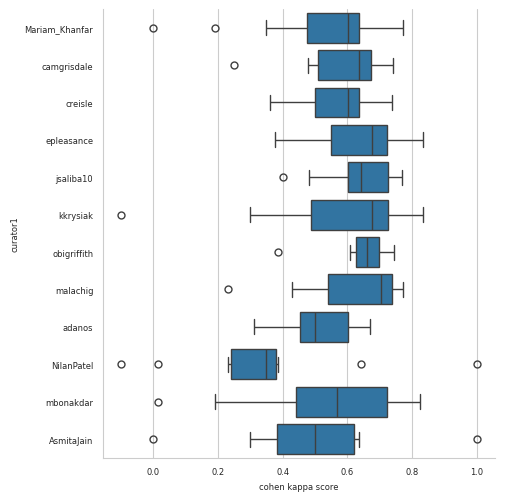

<Figure size 1000x1600 with 0 Axes>

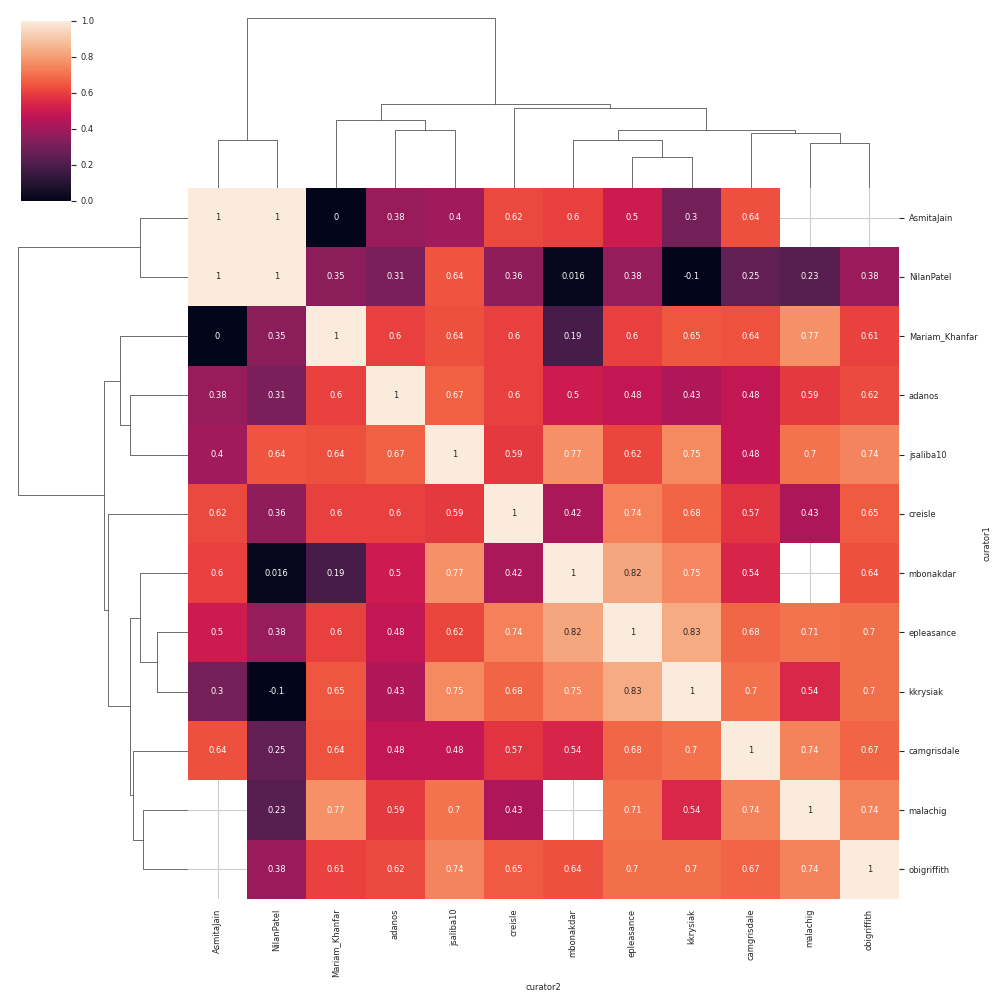

In [6]:
from sklearn.metrics import cohen_kappa_score
import itertools
import numpy as np
from figutils import plot_heatmap
import seaborn as sns

curators = [c for c in df.curator.unique().tolist()]
scores = []
np.seterr(all='raise')
MIN_SHARED_EXAMPLES = 3
sns.set_style('whitegrid')


for (curator1, curator2) in itertools.product(curators, repeat=2):
    cur1_df = df[df.curator == curator1].rename(columns={'predicted_label_name': 'curator1'})[['curator1', 'display_id']]
    cur2_df = df[df.curator == curator2].rename(columns={'predicted_label_name': 'curator2'})[['curator2', 'display_id']]

    cur_df = cur1_df.merge(cur2_df)
    if cur_df.shape[0] < MIN_SHARED_EXAMPLES:

        print('too few examples', cur_df.shape[0], 'to calculate agreement between', curator1, 'and', curator2)
        continue
    score = cohen_kappa_score(cur_df['curator1'].tolist(), cur_df['curator2'].tolist())
    scores.append({'curator1': curator1, 'curator2': curator2, 'score': score, 'shared_examples_count': cur_df.shape[0]})

scores_df = pd.DataFrame.from_records(scores)
print('average score:', scores_df[scores_df.curator1 != scores_df.curator2].score.mean())
print('average count:', scores_df[scores_df.curator1 != scores_df.curator2].shared_examples_count.mean())
scores_df['w_score'] = scores_df.shared_examples_count * scores_df.score
weight_avg = scores_df.w_score.sum() / scores_df.shared_examples_count.sum()
print('weighted avg:', weight_avg)
fig = sns.catplot(scores_df[scores_df.curator1 != scores_df.curator2], y='curator1', x='score', kind='box', weights='shared_examples_count' )
fig.set(xlabel='cohen kappa score')
plot_heatmap(scores_df, rows_col='curator1', cols_col='curator2', data_col='score', col_cluster=True, row_cluster=True)

In [7]:
# calculate Fleiss Kappa score: https://en.wikipedia.org/wiki/Fleiss%27_kappa

# Let N be the total number of elements, let n be the number of ratings per element, and let k be the number of categories into which assignments are made. The elements are indexed by i = 1, ..., N and the categories are indexed by j = 1, ..., k. Let nij represent the number of raters who assigned the i-th element to the j-th category.
# First calculate pj, the proportion of all assignments which were to the j-th category:
from irrCAC.raw import CAC
import statistics


N = df.display_id.nunique()
n = 3

scores = []

rate_df = pd.pivot_table(df, values='predicted_label_name', aggfunc='first', index='display_id', columns='curator')
fk = CAC(rate_df).fleiss()

scores = [{**fk['est'], 'round': 'overall', 'n_examples': df[['round', 'display_id']].drop_duplicates().shape[0], 'n_curators': df.curator.nunique()}]


for round_name, subset_df in df.groupby('round'):
    curators = subset_df.curator.unique().tolist()
    rate_df = pd.pivot_table(subset_df, values='predicted_label_name', aggfunc='first', index='display_id', columns='curator')
    fk = CAC(rate_df).fleiss()

    scores.append({**fk['est'], 'round': round_name,  'n_examples': subset_df[['round', 'display_id']].drop_duplicates().shape[0], 'n_curators': len(curators)})

scores_df = pd.DataFrame.from_records(scores)
scores_df

,coefficient_value,coefficient_name,confidence_interval,p_value,z,se,pa,pe,round,n_examples,n_curators
0,0.65255,Fleiss' kappa,"(0.61236, 0.69274)",0.000000e+00,31.89460,0.02046,0.77895,0.36378,overall,560,12
1,0.71554,Fleiss' kappa,"(0.61706, 0.81402)",0.000000e+00,14.63462,0.04889,0.81542,0.35114,1,46,7
2,0.64284,Fleiss' kappa,"(0.58591, 0.69977)",0.000000e+00,22.22203,0.02893,0.77444,0.36848,2023.10.20,300,9
3,0.46627,Fleiss' kappa,"(0.34113, 0.59142)",6.255574e-11,7.39976,0.06301,0.72222,0.47955,2025.01.31,93,11
4,0.72156,Fleiss' kappa,"(0.64063, 0.8025)",0.000000e+00,17.65256,0.04088,0.81983,0.35294,2025.05.01,121,11




In [40]:
## commonly confused?
from figutils import add_bar_labels
import matplotlib.pylab as pylab
from matplotlib import pyplot as plt

# params = {'legend.fontsize': 'x-large',
#           'figure.figsize': (15, 5),
#          'axes.labelsize': 'xx-large',
#          'axes.titlesize':'xx-large',
#          'xtick.labelsize':'x-large',
#          'ytick.labelsize':'x-large'}
# pylab.rcParams.update(params)

df['id'] = df['round'] + ' ' + df['display_id']
conf_df = df[['id', 'curator', 'predicted_label_name', 'round']].dropna(how='any').merge(df[['id', 'round', 'curator', 'predicted_label_name']].dropna(how='any').rename(columns={'curator': 'curator2', 'predicted_label_name': 'predicted_label_name2'}))
conf_df = conf_df[conf_df.curator < conf_df.curator2]
conf_df['freq'] = 1
total = conf_df.freq.sum()
conf_df['pair'] = conf_df.apply(lambda row: '\n/ '.join(sorted(set([row['predicted_label_name'], row['predicted_label_name2']]))), axis=1)
# conf_df.loc[~conf_df.pair.str.contains(' vs '), 'pair'] = 'Agreement'
conf_df['Agreement'] = True
conf_df.loc[conf_df.pair.str.contains('/ '), 'Agreement'] = False
# conf_df = conf_df.groupby('pair').agg({'freq': 'sum'}).reset_index()
# conf_df['freq'] = (100 *conf_df['freq'] / total).round()
plt.rc('font', size=16)
# plt.figure(figsize=(20, 8), dpi=600)
fig = sns.catplot(conf_df.sort_values('pair'), x='pair', kind='count',stat='percent', palette='tab20', hue='Agreement')
fig.fig.set_dpi(600)
fig.fig.set_size_inches(20, 6)


add_bar_labels(fig, fmt=lambda x: round(x, 1))

conf_df = df[['id', 'curator', 'predicted_label_name', 'round']].dropna(how='any').merge(df[['id', 'round', 'curator', 'predicted_label_name']].dropna(how='any').rename(columns={'curator': 'curator2', 'predicted_label_name': 'predicted_label_name2'}))
conf_df =conf_df[conf_df.curator < conf_df.curator2]
conf_df['freq'] = 1
# conf_df = conf_df[conf_df.predicted_label_name != conf_df.predicted_label_name2]
# ht_df = pd.pivot_table(conf_df, index='predicted_label_name', columns='predicted_label_name2', values='freq', aggfunc=lambda ser: 100* ser.sum() / conf_df.freq.sum())
# fig = sns.heatmap(ht_df, annot=True, fmt=".1f",  annot_kws=dict(fontsize='x-large'), cmap='Blues') #sns.color_palette("ch:s=.25,rot=-.25", as_cmap=True))
# fig.set(xlabel='Curator 1', ylabel='Curator 2')